In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
columns = [
    "class", "cap-shape", "cap-surface", "cap-color",
    "bruises", "odor", "gill-attachment", "gill-spacing",
    "gill-size", "gill-color", "stalk-shape", "stalk-root",
    "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring",
    "veil-type", "veil-color", "ring-number", "ring-type",
    "spore-print-color", "population", "habitat"
]

df = pd.read_csv(
    "agaricus-lepiota.data",
    header=None,
    names=columns
)

df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
mushrooms = df[["class", "odor", "spore-print-color"]].copy()

mushrooms = mushrooms.rename(columns={
    "class": "Edible_or_Poisonous",
    "odor": "Odor",
    "spore-print-color": "Spore_Print_Color"
})

mushrooms.head()

,Edible_or_Poisonous,Odor,Spore_Print_Color
0,p,p,k
1,e,a,n
2,e,l,n
3,p,p,k
4,e,n,n


In [4]:
# Convert edible/poisonous to numbers
mushrooms["Edible_or_Poisonous"] = mushrooms[
    "Edible_or_Poisonous"
].map({"e": 0, "p": 1})

# Convert odor to numbers
odor_codes = sorted(mushrooms["Odor"].unique())
odor_mapping = {
    code: i for i, code in enumerate(odor_codes)
}

mushrooms["Odor"] = mushrooms["Odor"].map(odor_mapping)

# Convert spore print color to numbers
spore_codes = sorted(mushrooms["Spore_Print_Color"].unique())
spore_mapping = {
    code: i for i, code in enumerate(spore_codes)
}

mushrooms["Spore_Print_Color"] = mushrooms[
    "Spore_Print_Color"
].map(spore_mapping)

# Display the updated data
mushrooms.head()

,Edible_or_Poisonous,Odor,Spore_Print_Color
0,1,6,2
1,0,0,3
2,0,3,3
3,1,6,2
4,0,5,3


In [5]:
mushrooms.isnull().sum()

Edible_or_Poisonous    0
Odor                   0
Spore_Print_Color      0
dtype: int64

In [6]:
# Display basic information about the dataset
print("Dataset Information:")
mushrooms.info()

print("\nSummary Statistics:")
print(mushrooms.describe())

print("\nNumber of Mushrooms:")
print(len(mushrooms))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Edible_or_Poisonous  8124 non-null   int64
 1   Odor                 8124 non-null   int64
 2   Spore_Print_Color    8124 non-null   int64
dtypes: int64(3)
memory usage: 190.5 KB

Summary Statistics:
       Edible_or_Poisonous         Odor  Spore_Print_Color
count          8124.000000  8124.000000        8124.000000
mean              0.482029     4.144756           3.596750
std               0.499708     2.103729           2.382663
min               0.000000     0.000000           0.000000
25%               0.000000     2.000000           2.000000
50%               0.000000     5.000000           3.000000
75%               1.000000     5.000000           7.000000
max               1.000000     8.000000           8.000000

Number of Mushrooms:
8124


In [7]:
# Show how frequently each value appears
for column in mushrooms.columns:
    print("\nDistribution of", column)
    print(mushrooms[column].value_counts().sort_index())


Distribution of Edible_or_Poisonous
Edible_or_Poisonous
0    4208
1    3916
Name: count, dtype: int64

Distribution of Odor
Odor
0     400
1     192
2    2160
3     400
4      36
5    3528
6     256
7     576
8     576
Name: count, dtype: int64

Distribution of Spore_Print_Color
Spore_Print_Color
0      48
1    1632
2    1872
3    1968
4      48
5      72
6      48
7    2388
8      48
Name: count, dtype: int64


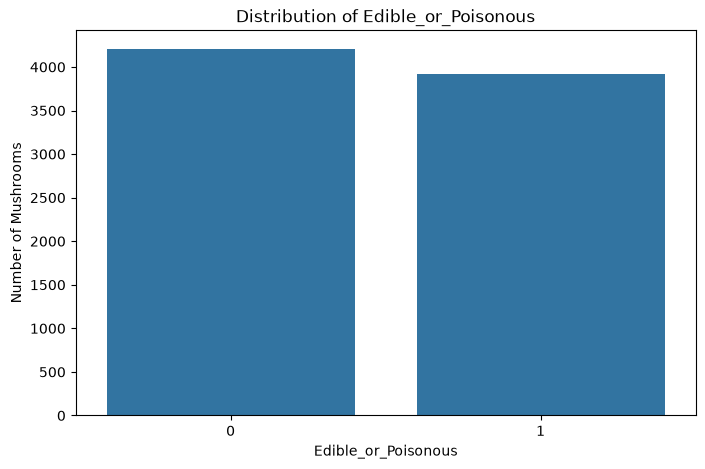

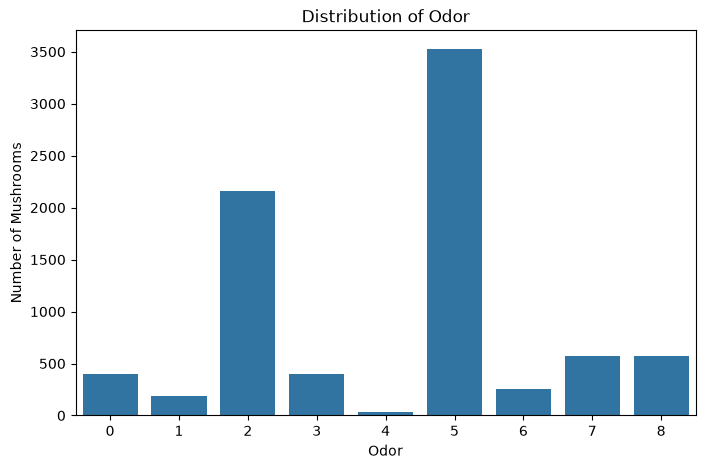

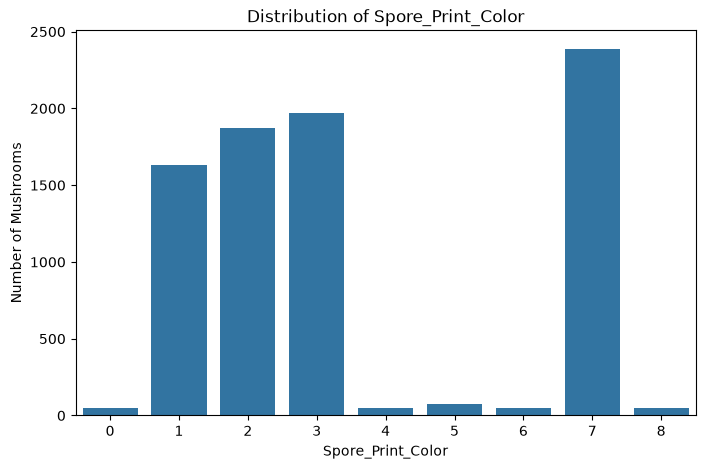

In [8]:
# Create a bar chart for each column
for column in mushrooms.columns:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=mushrooms,
        x=column
    )

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Number of Mushrooms")

    plt.show()

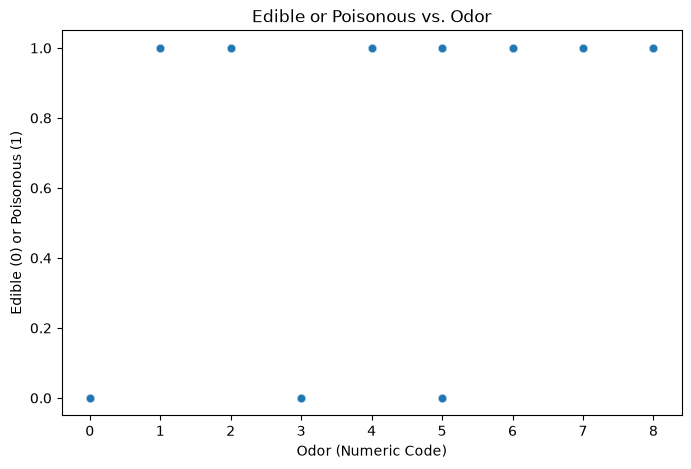

In [9]:
# Scatterplot: Edible/Poisonous vs. Odor

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=mushrooms,
    x="Odor",
    y="Edible_or_Poisonous",
    alpha=0.3
)

plt.title("Edible or Poisonous vs. Odor")
plt.xlabel("Odor (Numeric Code)")
plt.ylabel("Edible (0) or Poisonous (1)")

plt.show()

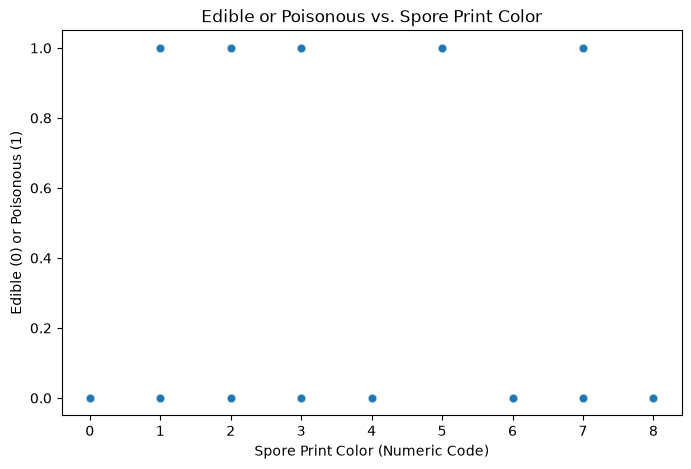

In [10]:
# Scatterplot: Edible/Poisonous vs. Spore Print Color

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=mushrooms,
    x="Spore_Print_Color",
    y="Edible_or_Poisonous",
    alpha=0.3
)

plt.title("Edible or Poisonous vs. Spore Print Color")
plt.xlabel("Spore Print Color (Numeric Code)")
plt.ylabel("Edible (0) or Poisonous (1)")

plt.show()

In this assignment, I analyzed the UCI Mushroom dataset to explore whether odor and spore-print color could help predict if a mushroom is edible or poisonous.

I selected three columns and converted their categorical values into numbers to prepare the data for machine learning with scikit-learn.

The distribution charts showed how frequently each category appeared, while the scatterplots compared odor and spore-print color with mushroom edibility. Because the data is categorical, some points overlap in the scatterplots.

Both odor and spore-print color are potential predictors of mushroom edibility. However, the scatterplots alone do not establish which variable is more useful. Further analysis using a classification model could help determine which characteristic is the better predictor.